# Qwen ESCI v1 LoRA — first-run review

This notebook reviews the first completed `qwen-esci-v1-lora` Azure ML run. It loads the archived run artifacts, joins scores back to ESCI query/product text, and creates two kinds of examples:

1. **Clean orderings** where the learned score follows `E > S > C > I`.
2. **Review candidates** where scores and labels strongly disagree, plus selected malformed or ambiguous queries.

A disagreement is not automatically a bad label: it can be a model error, an annotation issue, or an ambiguous query. The product text is included so that this distinction can be inspected manually.

In [1]:
import json
import os
from io import BytesIO, StringIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

LABEL_GRADE = {"E": 3, "S": 2, "C": 1, "I": 0}
LABEL_ORDER = ["E", "S", "C", "I"]
TOP_K = 10


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "config/prompts/esci_v1.txt").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the product_reco_gpu_lab project root.")


def find_dataset_dir(project_root: Path) -> Path:
    configured = os.getenv("ESCI_DATA_PATH")
    candidates = [
        Path(configured).expanduser() if configured else None,
        project_root.parent / "ext_repos/esci-data/shopping_queries_dataset",
        project_root / "data/shopping_queries_dataset",
    ]
    for candidate in candidates:
        if candidate is not None and candidate.is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not locate ESCI. Set ESCI_DATA_PATH to shopping_queries_dataset."
    )


PROJECT_ROOT = find_project_root()
DATASET_DIR = find_dataset_dir(PROJECT_ROOT)
RUN_ARCHIVE = Path(
    os.getenv(
        "ESCI_RUN_ARCHIVE",
        PROJECT_ROOT / "run_results/Job_qwen-esci-v1-lora_OutputsAndLogs.zip",
    )
).expanduser().resolve()

if not RUN_ARCHIVE.is_file():
    raise FileNotFoundError(
        f"Run archive not found: {RUN_ARCHIVE}. Set ESCI_RUN_ARCHIVE to override."
    )

print(f"Project root: {PROJECT_ROOT.name}")
print(f"Dataset directory: {DATASET_DIR.name}")
print(f"Run archive: {RUN_ARCHIVE.name}")

Project root: product_reco_gpu_lab
Dataset directory: shopping_queries_dataset
Run archive: Job_qwen-esci-v1-lora_OutputsAndLogs.zip


In [2]:
with ZipFile(RUN_ARCHIVE) as archive:
    metrics = json.loads(archive.read("evaluation/metrics.json"))
    predictions = pd.read_parquet(
        BytesIO(archive.read("evaluation/predictions.parquet"))
    )
    per_query = pd.read_json(
        StringIO(
            archive.read("evaluation/per_query_metrics.jsonl").decode("utf-8")
        ),
        lines=True,
    )

print(
    f"Loaded {len(predictions):,} scored products across "
    f"{predictions['query_id'].nunique():,} queries."
)

Loaded 20,255 scored products across 1,000 queries.


## 1. Headline results

Precision answers *how clean the first 10 results are*. Recall answers *what fraction of all relevant candidates fit inside those 10 slots*. Consequently, Recall@10 has a hard ceiling below 1 whenever a query has more than 10 relevant candidates.

In [3]:
ranking = metrics["ranking"]
training_epoch = metrics["training"]["epochs"][-1]
headline = pd.DataFrame(
    {
        "value": {
            "NDCG@10": ranking["ndcg@10"],
            "Direct Precision@10 (E/S)": ranking["direct_precision@10"],
            "Direct Recall@10 (E/S)": ranking["direct_recall@10"],
            "Broad Precision@10 (E/S/C)": ranking["broad_precision@10"],
            "Broad Recall@10 (E/S/C)": ranking["broad_recall@10"],
            "Training pair accuracy": training_epoch["pair_accuracy"],
            "Mean RankNet loss": training_epoch["mean_ranknet_loss"],
        }
    }
)
display(headline.style.format({"value": "{:.4f}"}))

direct_counts = per_query["direct_relevant_candidate_count"]
broad_counts = per_query["broad_relevant_candidate_count"]
direct_ceiling = (direct_counts.clip(upper=TOP_K) / direct_counts).mean()
broad_ceiling = (broad_counts.clip(upper=TOP_K) / broad_counts).mean()
ceiling = pd.DataFrame(
    {
        "actual_recall@10": [ranking["direct_recall@10"], ranking["broad_recall@10"]],
        "oracle_recall@10_ceiling": [direct_ceiling, broad_ceiling],
    },
    index=["direct (E/S)", "broad (E/S/C)"],
)
ceiling["fraction_of_ceiling"] = (
    ceiling["actual_recall@10"] / ceiling["oracle_recall@10_ceiling"]
)
display(Markdown("### Recall interpreted against its top-10 ceiling"))
display(ceiling.style.format("{:.4f}"))

,value
Broad Precision@10 (E/S/C),0.8954
Broad Recall@10 (E/S/C),0.6147
Direct Precision@10 (E/S),0.8593
Direct Recall@10 (E/S),0.6341
Mean RankNet loss,0.4237
NDCG@10,0.8521
Training pair accuracy,0.7987


### Recall interpreted against its top-10 ceiling

,actual_recall@10,oracle_recall@10_ceiling,fraction_of_ceiling
direct (E/S),0.6341,0.6990,0.9071
broad (E/S/C),0.6147,0.6626,0.9278


## 2. Join predictions to query and product text

Only the 1,000 evaluated query groups and their product IDs are read from the source Parquet files. No machine-specific absolute path is stored in the notebook.

In [4]:
examples_path = DATASET_DIR / "shopping_queries_dataset_examples.parquet"
products_path = DATASET_DIR / "shopping_queries_dataset_products.parquet"
eval_query_ids = predictions["query_id"].drop_duplicates().astype(int).tolist()
eval_product_ids = predictions["product_id"].drop_duplicates().astype(str).tolist()

examples = pq.read_table(
    examples_path,
    columns=["query_id", "query", "product_id", "product_locale", "esci_label"],
    filters=[
        ("split", "=", "test"),
        ("product_locale", "=", "us"),
        ("query_id", "in", eval_query_ids),
    ],
).to_pandas()
products = pq.read_table(
    products_path,
    columns=[
        "product_id",
        "product_locale",
        "product_title",
        "product_brand",
        "product_color",
    ],
    filters=[
        ("product_locale", "=", "us"),
        ("product_id", "in", eval_product_ids),
    ],
).to_pandas()

example_text = examples.drop_duplicates(["query_id", "product_id"])[
    ["query_id", "query", "product_id", "product_locale", "esci_label"]
]
product_text = products.drop_duplicates(["product_id", "product_locale"])
enriched = predictions.merge(
    example_text, on=["query_id", "product_id"], how="left", validate="one_to_one"
).merge(
    product_text, on=["product_id", "product_locale"], how="left", validate="many_to_one"
)
if not enriched["gold_label"].equals(enriched["esci_label"]):
    raise AssertionError("Archived labels do not match the source ESCI rows.")
enriched["grade"] = enriched["gold_label"].map(LABEL_GRADE)

print(f"Joined rows: {len(enriched):,}")
print(f"Missing titles: {enriched['product_title'].isna().sum():,}")

Joined rows: 20,255
Missing titles: 0


### Aggregate score separation by ESCI label

,products,mean_score,median_score,top_10_rate,mean_rank
gold_label,,,,,
E,9075,1.461,1.383,61.2%,10.84
S,6818,0.170,-0.055,44.5%,13.42
C,1010,-1.284,-1.590,35.6%,14.92
I,3352,-1.811,-2.070,31.1%,17.10


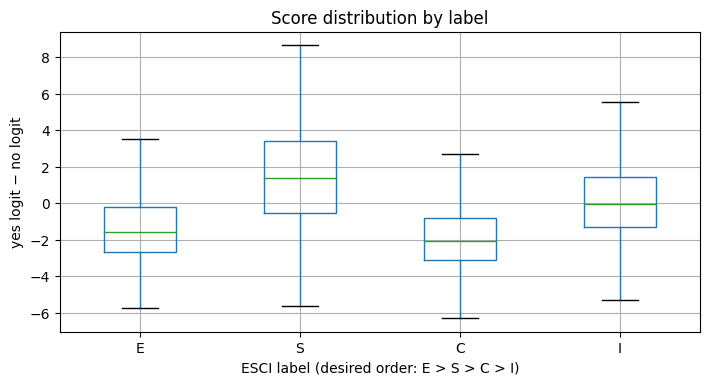

In [5]:
label_summary = (
    enriched.groupby("gold_label", observed=True)
    .agg(
        products=("product_id", "size"),
        mean_score=("ranking_score", "mean"),
        median_score=("ranking_score", "median"),
        top_10_rate=("predicted_rank", lambda values: (values <= TOP_K).mean()),
        mean_rank=("predicted_rank", "mean"),
    )
    .reindex(LABEL_ORDER)
)
display(Markdown("### Aggregate score separation by ESCI label"))
display(
    label_summary.style.format(
        {"mean_score": "{:.3f}", "median_score": "{:.3f}", "top_10_rate": "{:.1%}", "mean_rank": "{:.2f}"}
    )
)

fig, ax = plt.subplots(figsize=(8, 4))
enriched.boxplot(
    column="ranking_score", by="gold_label", positions=range(1, 5), ax=ax, showfliers=False
)
ax.set_xticklabels(LABEL_ORDER)
ax.set_xlabel("ESCI label (desired order: E > S > C > I)")
ax.set_ylabel("yes logit − no logit")
ax.set_title("Score distribution by label")
fig.suptitle("")
plt.show()

## 3. Query-level label ordering

For every query, all differently labeled product pairs are compared. A pair is correct when the product with the higher ESCI grade also has the higher model score. `strict_separation=True` means **every** cross-label pair is correctly separated—not merely that the label means are ordered.

In [6]:
def query_order_statistics(group: pd.DataFrame) -> dict:
    rows = list(group[["gold_label", "ranking_score"]].itertuples(index=False, name=None))
    comparisons = 0
    correct = 0
    worst_inversion_gap = 0.0
    for left_index, (left_label, left_score) in enumerate(rows):
        for right_label, right_score in rows[left_index + 1 :]:
            left_grade = LABEL_GRADE[left_label]
            right_grade = LABEL_GRADE[right_label]
            if left_grade == right_grade:
                continue
            comparisons += 1
            higher_score, lower_score = (
                (left_score, right_score)
                if left_grade > right_grade
                else (right_score, left_score)
            )
            if higher_score > lower_score:
                correct += 1
            else:
                worst_inversion_gap = max(
                    worst_inversion_gap, lower_score - higher_score
                )
    observed_labels = [
        label for label in LABEL_ORDER if label in set(group["gold_label"])
    ]
    label_means = group.groupby("gold_label")["ranking_score"].mean()
    return {
        "query_id": group["query_id"].iloc[0],
        "query": group["query"].iloc[0],
        "candidate_count": len(group),
        "labels_present": "".join(observed_labels),
        "cross_label_pairs": comparisons,
        "pair_order_accuracy": correct / comparisons if comparisons else float("nan"),
        "mean_label_ordered": all(
            label_means[higher] > label_means[lower]
            for higher, lower in zip(observed_labels, observed_labels[1:])
        ),
        "strict_separation": comparisons > 0 and correct == comparisons,
        "worst_inversion_gap": worst_inversion_gap,
    }


def inspection_table(query_ids, max_products_per_query=30):
    columns = [
        "query_id", "query", "predicted_rank", "gold_label",
        "ranking_score", "product_id", "product_title",
        "product_brand", "product_color",
    ]
    selected = enriched[enriched["query_id"].isin(query_ids)].copy()
    selected = selected.sort_values(["query_id", "predicted_rank"])
    return selected.groupby("query_id", sort=False).head(max_products_per_query)[columns]


order_stats = pd.DataFrame(
    query_order_statistics(group)
    for _, group in enriched.groupby("query_id", sort=False)
)
ndcg_column = next(column for column in per_query if column.startswith("ndcg@"))
order_stats = order_stats.merge(
    per_query[["query_id", ndcg_column]], on="query_id", how="left"
)

display(
    pd.DataFrame(
        {
            "value": {
                "mean same-query pair-order accuracy": order_stats["pair_order_accuracy"].mean(),
                "queries with strict cross-label separation": order_stats["strict_separation"].mean(),
                "queries with all four labels": order_stats["labels_present"].eq("ESCI").mean(),
            }
        }
    ).style.format({"value": "{:.2%}"})
)

,value
mean same-query pair-order accuracy,72.11%
queries with all four labels,12.90%
queries with strict cross-label separation,6.10%


## 4. Strong examples: correct `E > S > C > I` ordering

No evaluated query containing all four labels achieved perfect separation of every individual cross-label product pair. The following are therefore the strongest honest examples: all four **label means** follow `E > S > C > I`, and the queries are ranked by their individual pair-order accuracy. Products with the same label are intentionally unconstrained because the training data gives no preferred order within a label.

In [7]:
good_queries = (
    order_stats[
        order_stats["mean_label_ordered"] & order_stats["labels_present"].eq("ESCI")
    ]
    .sort_values(
        ["pair_order_accuracy", ndcg_column, "candidate_count"],
        ascending=[False, False, False],
    )
    .head(5)
)
display(good_queries.reset_index(drop=True))
display(inspection_table(good_queries["query_id"].tolist()))

,query_id,query,candidate_count,labels_present,cross_label_pairs,pair_order_accuracy,mean_label_ordered,strict_separation,worst_inversion_gap,ndcg@10
0,8820,american outdoor grills,16,ESCI,77,0.987013,True,False,1.273438,0.996346
1,52774,ikea drill,16,ESCI,72,0.986111,True,False,0.125000,0.994138
2,63293,logitech crayon for ipad,15,ESCI,76,0.960526,True,False,0.781250,0.985234
3,53430,insta360 one,16,ESCI,74,0.932432,True,False,2.859375,0.937633
4,5722,I would want a light weight protable laptop with a graphics card and alot of memory,39,ESCI,519,0.924855,True,False,4.070312,0.874233


,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
1705,5722,I would want a light weight protable laptop with a graphics card and alot of memory,1,S,5.414062,B07RF1XD36,"Acer Aspire 5 Slim Laptop, 15.6 inches Full HD IPS Display, AMD Ryzen 3 3200U, Vega 3 Graphics, 4GB DDR4, 128GB SSD,...",Acer,Silver
1672,5722,I would want a light weight protable laptop with a graphics card and alot of memory,2,E,5.226562,B081FZV45H,"2019 Apple MacBook Pro (16-inch, 16GB RAM, 512GB Storage, 2.6GHz Intel Core i7) - Space Gray",Apple,Space Gray
1675,5722,I would want a light weight protable laptop with a graphics card and alot of memory,3,E,4.664062,B086383HC7,"Lenovo Chromebook Flex 5 13"" Laptop, FHD (1920 x 1080) Touch Display, Intel Core i3-10110U Processor, 4GB DDR4 Onboa...",Lenovo,Graphite Grey
1708,5722,I would want a light weight protable laptop with a graphics card and alot of memory,4,E,4.625000,B07TWHYTSQ,"Lenovo Flex 14 2-in-1 Convertible Laptop, 14 Inch FHD Touchscreen Display, AMD Ryzen 5 3500U Processor, 12GB DDR4 RA...",Lenovo,Onyx Black
1681,5722,I would want a light weight protable laptop with a graphics card and alot of memory,5,E,4.585938,B08LVJJ8LL,"2021 HP Stream 14"" HD Laptop Light-Weight, Intel N4020 (Up tp 2.8GHz), 4GB RAM, 64GB eMMC, Webcam, HDMI, WiFi, 1 Yea...",HP,Jet Black
1671,5722,I would want a light weight protable laptop with a graphics card and alot of memory,6,E,4.015625,B081D9HJ4P,"HP 14"" Touchscreen Home and Business Laptop Ryzen 3-3200U, 8GB RAM, 128GB M.2 SSD, Dual-Core up to 3.50 GHz, Vega 3 ...",HP,Black
1686,5722,I would want a light weight protable laptop with a graphics card and alot of memory,7,E,3.570312,B07ZWDTMKC,HP 15-dy1751ms Intel i5-1035G1 8GB DDR4 Memory 512GB SSD 15.6 Touch Screen,HP,None
1699,5722,I would want a light weight protable laptop with a graphics card and alot of memory,8,E,3.179688,B07GLV1VC7,"Lenovo Chromebook S330 Laptop, 14-Inch FHD (1920 x 1080) Display, MediaTek MT8173C Processor, 4GB LPDDR3, 64GB eMMC,...",Lenovo,Business Black
1684,5722,I would want a light weight protable laptop with a graphics card and alot of memory,9,E,3.015625,B091PKXT6Z,"2021 Lenovo Ideapad 3 15.6"" Touchscreen Laptop Computer Intel Quad-Core i5-10210U (Beats i7-8665U), 12GB DDR4 RAM, 1...",Lenovo,Almond
1691,5722,I would want a light weight protable laptop with a graphics card and alot of memory,10,E,2.921875,B07XW266D9,"SAMSUNG XE350XBA-K01US Chromebook 4 + Chrome OS 15.6"" Full HD Intel Celeron Processor N4000 4GB RAM 32Gb Emmc Gigabi...",Samsung Electronics,Silver


## 5. Strongest score/label inversions

For each query, this finds the single largest inversion: a lower-grade product scoring above a higher-grade product. Large gaps are useful review targets, but the table alone cannot determine whether the model or annotation is wrong.

In [8]:
def worst_inversion(group: pd.DataFrame):
    best = None
    rows = list(group.to_dict("records"))
    for left_index, left in enumerate(rows):
        for right in rows[left_index + 1 :]:
            if left["grade"] == right["grade"]:
                continue
            higher, lower = (left, right) if left["grade"] > right["grade"] else (right, left)
            gap = lower["ranking_score"] - higher["ranking_score"]
            if gap <= 0 or (best is not None and gap <= best["inversion_gap"]):
                continue
            best = {
                "query_id": higher["query_id"],
                "query": higher["query"],
                "inversion_gap": gap,
                "higher_label": higher["gold_label"],
                "higher_score": higher["ranking_score"],
                "higher_title": higher["product_title"],
                "lower_label": lower["gold_label"],
                "lower_score": lower["ranking_score"],
                "lower_title": lower["product_title"],
            }
    return best


inversions = pd.DataFrame(
    inversion
    for _, group in enriched.groupby("query_id", sort=False)
    if (inversion := worst_inversion(group)) is not None
)
inversions = inversions.merge(
    per_query[["query_id", ndcg_column]], on="query_id", how="left"
)
worst_inversions = inversions.sort_values(
    ["inversion_gap", ndcg_column], ascending=[False, True]
).head(12)
display(worst_inversions.reset_index(drop=True))

display(Markdown("### Full rankings for the five largest inversions"))
display(inspection_table(worst_inversions["query_id"].head(5).tolist()))

,query_id,query,inversion_gap,higher_label,higher_score,higher_title,lower_label,lower_score,lower_title,ndcg@10
0,1957,128oz lube,10.851562,E,-4.914062,DrinkTanks 128 oz Vacuum Insulated Stainless Steel Beer Growler,S,5.937500,"Wet Original Water Based Sex Lube 128 Ounce Premium Personal Lubricant, Long Lasting Formula for Condom Safe Vegan P...",0.910451
1,36476,easieeaters curved utensils right handed without shields,10.109375,E,-5.656250,"Crimson Trace LG-105 Lasergrips with Red Laser, Heavy Duty Construction and Instinctive Activation for S&W J-Frame R...",S,4.453125,Easie Eaters Fork and Spoon(Style=Left Handed),0.815619
2,76433,otterbox 6se phone case,9.304688,E,-1.078125,"OtterBox Defender Series Replacement Holster/Belt Clip for Apple iPhone 5, iPhone 5S, iPhone 5C, iPhone SE (1st GEN ...",I,8.226562,"Otterbox Symmetry Series Case for Iphone 6/6s (4.7"" Version) - Retail Packaging - Prevail (Coral/Gunmetal Grey)",0.779908
3,110930,white and blue fishing reel,9.195312,S,-3.648438,"Reel Grip 1144 Reel Handle Cover, Patriotic Tie Dye Finish",C,5.546875,"Okuma Fishing TU-702-50 Tundra Combo Spinning Reel (Large, White/Blue)",0.699768
4,73095,new balance mens orange,8.906250,E,-2.414062,"New Balance Men's 574 V2 Essential Sneaker, Varsity Orange, 17 XW US",S,6.492188,New Balance Mens X90 Orange,0.677835
5,70411,monk fruit sweetener without erythritol,8.234375,S,-4.203125,"SmartyPants Women's Formula Gummy Vitamins: Gluten Free, Multivitamin, CoQ10, Folate (Methylfolate), Vitamin K2, Vit...",I,4.031250,"LLINEA MONK FRUIT - Approx. 200 Servings Per Bottle - 6 Drops = 1 Tsp of Sugar - Sweeten Coffee, Tea, Smoothies, & M...",0.844355
6,37126,electric ride on vehicles for kids,8.226562,E,-2.593750,Peg Perego John Deere Ground Force Tractor with Trailer,S,5.632812,"Electric Motorcycle for Kids – 3-Wheel Battery Powered Motorbike for Kids Ages 3 -6 – Fun Decals, Reverse, and Headl...",0.830201
7,78470,pearl percussion kit,8.109375,E,-4.679688,Vic Firth V7806B Traveler Bag Kit,I,3.429688,"Pearl Tech Tool combination Drum Key and Drum Set Multi-Tool with five Screwdrivers, six Hex Keys and Bottle Opener,",0.559345
8,87942,roasting pan for 30 lb turkey,7.960938,S,-0.835938,Cuisinart 7117-14RR Lasagna Pan with Stainless Roasting Rack,C,7.125000,"Reynolds Kitchens Turkey Size Roaster Pan, Holds Up to 30lbs, 1 Count",0.569403
9,57921,kids nylon backpack,7.953125,E,-2.734375,80 Pack Drawstring Backpack Bulk Drawstring Bags With 20 Colors Waterproof Draw String Bags Pack DIY Available Cinch...,S,5.218750,"Bixbee Kids Backpack, Signature Series Purple, Medium",0.920650


### Full rankings for the five largest inversions

,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
992,1957,128oz lube,1,E,6.359375,B000C14OOK,"TriFlow Superior lube, 128oz (1 Gallon) ORM-D",TriFlow,Black
997,1957,128oz lube,2,S,5.937500,B001H0AXRW,"Wet Original Water Based Sex Lube 128 Ounce Premium Personal Lubricant, Long Lasting Formula for Condom Safe Vegan P...",WET,Translucent
990,1957,128oz lube,3,E,5.671875,B002R5BCYE,"ID Lubricants Glide 128 Fl Oz Natural Feel Water-Based Personal Lubricant, Clear, 128 Oz",ID Lubricants,Clear
986,1957,128oz lube,4,E,4.820312,B06WRV546X,Spunk Lube Hybrid (128 Ounce (1 Gallon)),Spunk,None
984,1957,128oz lube,5,E,3.367188,B077SPJN4B,"Spunk Pure Silicone Lubricant, (128 Ounce)",Spunk,None
987,1957,128oz lube,6,E,2.953125,B01LMOKE12,"Wet Original Gel Lubricant Water Based One Gallon, 128 Ounce by Wet",WET,None
988,1957,128oz lube,7,E,1.351562,B00VNI1JI0,"UltraPro Food Grade Mineral Oil, 1 Gallon (128oz), for Lubricating and Protecting Cutting Board, Butcher Block, Stai...",UltraSource,Original Version
995,1957,128oz lube,8,S,-0.835938,B001H0AYNK,Wet Platinum Silicone Based Sex Lube Gallon Premium Personal Luxury Lubricant for Men Women & Couples. More Long Las...,WET,Silicone Based - Platinum
993,1957,128oz lube,9,S,-1.335938,B000HHLYPG,Durvet OB All Purpose Lubricant Gallon,Durvet,None
991,1957,128oz lube,10,S,-1.476562,B0094VCX5Q,Wet Gallon Original Body Glide,Wet Lube,None


## 6. Curated annotation-quality review cases

These queries were selected after inspecting the low-NDCG tail. Several look malformed, encode exclusions/negation, or appear to have labels that do not match the literal query. They are especially useful for separating ranking failures from dataset noise.

In [9]:
CURATED_REVIEW_NOTES = {
    606: "Malformed query; several E labels appear unrelated to the literal text.",
    33810: "Ambiguous intent: channel/subscription wording versus physical Disney products.",
    74074: "Natural-language complaint/non-shopping query with surprising E annotations.",
    55882: "Explicit 'without cross' constraint; inspect whether labels honor the exclusion.",
    20080: "Explicit 'without envelopes' constraint; useful negation/constraint case.",
}
curated_ids = [query_id for query_id in CURATED_REVIEW_NOTES if query_id in set(enriched["query_id"])]
curated_summary = order_stats[order_stats["query_id"].isin(curated_ids)].copy()
curated_summary["review_reason"] = curated_summary["query_id"].map(CURATED_REVIEW_NOTES)
display(curated_summary.sort_values(ndcg_column).reset_index(drop=True))
display(inspection_table(curated_ids))

,query_id,query,candidate_count,labels_present,cross_label_pairs,pair_order_accuracy,mean_label_ordered,strict_separation,worst_inversion_gap,ndcg@10,review_reason
0,606,0zo not bit,33,EI,116,0.370690,False,False,2.031250,0.00000,Malformed query; several E labels appear unrelated to the literal text.
1,33810,disney plus channel,16,EI,15,0.000000,False,False,1.640625,0.00000,Ambiguous intent: channel/subscription wording versus physical Disney products.
2,74074,no it's not his bike,16,EI,28,0.000000,False,False,3.453125,0.00000,Natural-language complaint/non-shopping query with surprising E annotations.
3,55882,jesus without cross,40,ESI,179,0.245810,False,False,3.148438,0.23133,Explicit 'without cross' constraint; inspect whether labels honor the exclusion.
4,20080,brown notecards without envelopes,40,ESCI,483,0.536232,False,False,1.804688,0.27115,Explicit 'without envelopes' constraint; useful negation/constraint case.


,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
177,606,0zo not bit,1,I,-2.171875,B00GMXFK3G,"DEWALT Screwdriver Bit Set, Impact Ready, FlexTorq, 40-Piece (DWA2T40IR)",DEWALT,"Black/Silver IMPACT READY FlexTorq Screw Driving Set, 40-Piece"
168,606,0zo not bit,2,I,-2.414062,B07YWRXVP6,"Willful Smart Watch for Android Phones and iOS Phones Compatible iPhone Samsung, IP68 Swimming Waterproof Smartwatch...",Willful,None
164,606,0zo not bit,3,I,-2.531250,B087C1R9QW,"YAMAY Smart Watch, Watches for Men Women Fitness Tracker Blood Pressure Monitor Blood Oxygen Meter Heart Rate Monito...",YAMAY,Pink
184,606,0zo not bit,4,I,-2.945312,B0795DJXNH,"Car Charger, AINOPE 4.8A All Metal Car Charger Adapter Mini Flush Fit USB Car Charger Dual Port Charging Compatible ...",AINOPE,Black
169,606,0zo not bit,5,I,-3.015625,B07M9ZF35W,"LEXIVON Torx Bit Socket Set, Premium S2 Alloy Steel | 13-Piece Star T8 - T60 Set | Enhanced Storage Case (LX-143)",LEXIVON,Black
...,...,...,...,...,...,...,...,...,...
13277,74074,no it's not his bike,12,I,-4.382812,B01LY3QXGP,"Mancro Laptop Backpack, Business Water Resistant Laptop bag Backpack Gift for Men Women with USB Charging Port, Anti...",Mancro,Austere Grey
13269,74074,no it's not his bike,13,I,-4.757812,B078WZSGGW,"Yes, they're Natural 20 d20 dice funny RPG gamer T Shirt",Shirts for Salty Gamers,Black
13278,74074,no it's not his bike,14,I,-4.945312,B01IP0DXGE,"I Love To Wrap Both My Hands Around It And Swallow, Funny Stemless Wine Glass, Perfect For Bachelorette Parties, Bri...",C & M Personal Gifts,Clear
13280,74074,no it's not his bike,15,E,-5.000000,B00JM5GW10,"Play-Doh Modeling Compound 10-Pack Case of Colors, Non-Toxic, Assorted, 2 oz. Cans, Ages 2 and up, Multicolor (Amazo...",Play-Doh,Multicolor


## 7. Manual review sheet

Use this table to record a judgment for each suspicious query. Suggested values are `model_error`, `label_error`, `ambiguous`, and `insufficient_product_text`. The optional export remains commented out so running the notebook does not silently create another artifact.

In [10]:
review_query_ids = list(
    dict.fromkeys(worst_inversions["query_id"].head(12).tolist() + curated_ids)
)
review_sheet = (
    order_stats[order_stats["query_id"].isin(review_query_ids)]
    [["query_id", "query", ndcg_column, "pair_order_accuracy", "worst_inversion_gap"]]
    .sort_values([ndcg_column, "worst_inversion_gap"], ascending=[True, False])
    .copy()
)
review_sheet["reviewer_judgment"] = ""
review_sheet["reviewer_notes"] = ""
display(review_sheet.reset_index(drop=True))

# Optional after filling the fields above:
# review_sheet.to_csv(PROJECT_ROOT / "run_results/qwen_esci_v1_manual_review.csv", index=False)

,query_id,query,ndcg@10,pair_order_accuracy,worst_inversion_gap,reviewer_judgment,reviewer_notes
0,74074,no it's not his bike,0.000000,0.000000,3.453125,,
1,606,0zo not bit,0.000000,0.370690,2.031250,,
2,33810,disney plus channel,0.000000,0.000000,1.640625,,
3,55882,jesus without cross,0.231330,0.245810,3.148438,,
4,20080,brown notecards without envelopes,0.271150,0.536232,1.804688,,
5,101981,the first years bottle,0.489235,0.311475,7.835938,,
6,78470,pearl percussion kit,0.559345,0.577778,8.109375,,
7,87942,roasting pan for 30 lb turkey,0.569403,0.411765,7.960938,,
8,73095,new balance mens orange,0.677835,0.316667,8.906250,,
9,110930,white and blue fishing reel,0.699768,0.575758,9.195312,,


## Takeaways

- Judge the trained run against the unmodified-Qwen baseline produced by `python jobs/submit_train_esci.py --eval-only`; absolute trained metrics alone do not measure improvement.
- Recall@10 should be read relative to its query-specific ceiling, because many ESCI queries have more than 10 relevant candidates.
- Aggregate score means can follow `E > S > C > I` while individual products still overlap substantially. Query-level pair accuracy and inversion examples expose that overlap.
- Do not automatically train harder on the suspicious cases. First classify them as model errors, annotation errors, ambiguous intent, or insufficient product text.